# DWN fault injection: which faults break the model?

This notebook takes the models you already trained and exported with `Final_DWN.ipynb` (the `*_spec.pkl` files) and injects
faults into the **table-lookup simulation**, the same one that matches PyTorch and the Verilog 100%. No retraining, no GPU.

**Fault models** (all at the model level, i.e. what the fault does to the DWN's truth tables, wires and counters):

| # | Fault | Hardware cause | Persistent? | Campaign |
|---|---|---|---|---|
| 1 | One LUT truth-table bit flips | SEU in the LUT's configuration memory (INIT bit) | yes, until scrubbing/reconfig | exhaustive: every bit of every LUT |
| 2 | LUT output stuck at 0 / 1 | permanent defect, aging, or an SEU that breaks the LUT's output routing | yes | exhaustive: every node × {0,1} |
| 3 | LUT input pin stuck at 0 / 1 | SEU in a routing switch (open/misrouted wire) | yes | exhaustive: every pin × {0,1} |
| 4 | One bit of a class-count register flips | transient SEU in a flip-flop of the popcount | no, one inference | exhaustive: every class × bit |
| 5 | Every LUT bit flips with probability *p* | many random upsets (the setup of arXiv 2603.22770) | yes | Monte Carlo, `BER_TRIALS` per *p* |

**How each fault is judged.** The fault-free run gives the *golden* output for every test sample: the class scores (the popcount
of each class) and the predicted class. Under a fault, every inference falls into one of four levels:

* **masked**: the class scores are exactly the same;
* **tolerable**: some class score moved, by at most `SCORE_THRESHOLD`, and the predicted class is the same;
* **significant**: some class score moved by more than `SCORE_THRESHOLD`, but the predicted class is still the same;
* **critical**: the predicted class changed.

Each fault gets the share of test inferences at each level, and a **fault level** = the worst level it causes on any test sample.
The accuracy drop is reported next to it.

`SCORE_THRESHOLD` is a fraction of the bits per class (0.1 = the score may move by 10% of its maximum). The notebook prints it in votes.

**Run:** put this notebook next to `Final_DWN.ipynb` (it reads `hw/` or a `run_N/` folder and `data/`), set the options, Run all.
Needs only `numpy`, `pandas`, `matplotlib`, plus `openml` + `scikit-learn` for JSC, all already in `requirements.txt`.

## Options

In [ ]:
MODEL = 'mnist_sm'        # mnist_sm, mnist_lg, jsc_sm10, jsc_sm50, jsc_md, jsc_lg
SPEC_DIR = 'hw'           # folder with <MODEL>_spec.pkl: 'hw' (all six models) or e.g. 'run_1'

SCORE_THRESHOLD = 0.1     # tolerable vs significant: largest class-score change, as a fraction of the bits per class (at least 1 vote)
ACC_THRESHOLD = 1.0       # campaign 5: 'tolerable BER' = largest p whose mean accuracy drop is at most this (percentage points)

# Campaigns 1-4 are exhaustive. Set a number to randomly sample that many faults instead (None = all).
MAX_FAULTS = None

# Campaign 5: random bit flips at bit error rate p
BER_LIST = [1e-5, 1e-4, 1e-3, 3e-3, 1e-2, 3e-2, 0.1, 0.2, 0.3, 0.5]
BER_TRIALS = 100          # Monte Carlo repetitions per p
BER_SAMPLES = 20000       # test samples used in campaign 5 (None = whole test set; JSC has 166k, so a subset is much faster)

SEED = 0
OUT_DIR = 'faults'        # results go to OUT_DIR/<MODEL>/

## Setup and data

The thermometer encoding is refitted on the training set exactly as `torch_dwn.DistributiveThermometer` does it, with the same JSC split as `Final_DWN` (`random_state=42`). The golden-run check below confirms the inputs are identical: the clean accuracy must equal the one in `results.csv`.

In [ ]:
import os, math, time, gzip, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = {'mnist_sm': ('mnist', 1), 'mnist_lg': ('mnist', 3),
        'jsc_sm10': ('jsc', 200), 'jsc_sm50': ('jsc', 200), 'jsc_md': ('jsc', 200), 'jsc_lg': ('jsc', 200)}
dataset, Z = DATA[MODEL]
OUT = os.path.join(OUT_DIR, MODEL)
os.makedirs(OUT, exist_ok=True)
rng = np.random.default_rng(SEED)

def load_mnist(root='data/MNIST/raw'):
    def idx(name, offset):
        for p in (f'{root}/{name}', f'{root}/{name}.gz'):
            if os.path.exists(p):
                return np.frombuffer((gzip.open if p.endswith('.gz') else open)(p, 'rb').read(), np.uint8, offset=offset)
        raise FileNotFoundError(p)
    if not os.path.exists(root):          # not downloaded yet: let torchvision fetch it
        from torchvision import datasets
        datasets.MNIST('./data', train=True, download=True); datasets.MNIST('./data', train=False, download=True)
    xtr = idx('train-images-idx3-ubyte', 16).reshape(-1, 784).astype(np.float32) / 255
    xte = idx('t10k-images-idx3-ubyte', 16).reshape(-1, 784).astype(np.float32) / 255
    yte = idx('t10k-labels-idx1-ubyte', 8).astype(np.int64)
    return xtr, xte, yte

def load_jsc():
    import openml
    from sklearn.model_selection import train_test_split
    ds = openml.datasets.get_dataset(42468)
    df_x, df_y, _, _ = ds.get_data(dataset_format='dataframe', target=ds.default_target_attribute)
    features = df_x.values.astype(np.float32)
    names = list(df_y.unique())
    labels = np.array(df_y.map(lambda v: names.index(v)).values)
    xtr, xte, ytr, yte = train_test_split(features, labels, train_size=0.8, random_state=42)
    return xtr, xte, yte.astype(np.int64)

def distributive_thermometer(x_train, z):
    # same as torch_dwn.DistributiveThermometer(z).fit(x_train): per-feature quantile thresholds
    s = np.sort(x_train, axis=0)
    idx = [int(s.shape[0] * i / (z + 1)) for i in range(1, z + 1)]
    return s[idx].T                                     # (features, z)

xtr, xte, y = load_mnist() if dataset == 'mnist' else load_jsc()
thr = distributive_thermometer(xtr, Z)
x_bits = (xte[:, :, None] > thr[None]).reshape(len(xte), -1).astype(np.uint8)
spec = pickle.load(open(f'{SPEC_DIR}/{MODEL}_spec.pkl', 'rb'))
print(MODEL, '| test samples', len(y), '| input bits', x_bits.shape[1],
      '| layers', [l['mapping'].shape[0] for l in spec['layers']], '| classes', spec['k'])

mnist_sm | test samples 10000 | input bits 784 | layers [1000, 500] | classes 10


## Fault-injecting simulator

It runs the fault-free model once and caches every LUT's address and output for every test sample. A fault then only recomputes the samples it can affect (for a LUT bit flip: the samples that actually read that entry), which is what makes the exhaustive campaigns fast.

In [ ]:
class DWNSim:
    def __init__(self, spec, x_bits, y):
        self.K, self.layers, self.y = spec['k'], spec['layers'], y
        self.N = len(y)
        self.addr, self.h = [], []                      # per layer: (N, J) LUT address and (N, J) LUT output
        h = np.asarray(x_bits, np.uint8)
        for layer in self.layers:
            a = self._address(h, layer['mapping'])
            h = layer['table'][np.arange(a.shape[1])[None, :], a].astype(np.uint8)
            self.addr.append(a); self.h.append(h)
        J = self.layers[-1]['mapping'].shape[0]
        self.G = math.ceil(J / self.K)                  # last-layer bits per class (same padding as Final_DWN)
        self.cls_of = np.arange(J) // self.G            # class each last-layer node votes for
        self.W = max(1, math.ceil(math.log2(self.G + 1)))   # class-count register width in the Verilog
        self.counts = self._counts(self.h[-1])
        self.pred = self.counts.argmax(1)
        self.correct = self.pred == y
        self.acc = self.correct.mean()
        self.T = max(1, int(round(SCORE_THRESHOLD * self.G)))   # score threshold in votes

    def _stats(self, rows, cnt):
        # rows = affected test samples, cnt = their faulty class scores -> levels and accuracy drop
        dev = np.abs(cnt - self.counts[rows]).max(1)
        p = cnt.argmax(1)
        crit = p != self.pred[rows]
        sig = ~crit & (dev > self.T)
        tol = ~crit & (dev > 0) & (dev <= self.T)
        drop = (int(self.correct[rows].sum()) - int((p == self.y[rows]).sum())) / self.N
        return {'tolerable': int(tol.sum()), 'significant': int(sig.sum()), 'critical': int(crit.sum()),
                'max_score_change': int(dev.max()) if len(dev) else 0, 'drop_pp': drop * 100}

    @staticmethod
    def _address(h, m):
        a = np.zeros((h.shape[0], m.shape[0]), dtype=np.int64)
        for l in range(m.shape[1]):
            a |= h[:, m[:, l]].astype(np.int64) << l
        return a

    def _counts(self, h_last):
        h = np.pad(h_last, ((0, 0), (0, self.K * self.G - h_last.shape[1])))
        return h.reshape(h.shape[0], self.K, self.G).sum(-1).astype(np.int64)

    def _propagate(self, li, h, tables=None):
        # h = (possibly faulty) output of layer li -> class scores
        for l in range(li + 1, len(self.layers)):
            t = self.layers[l]['table'] if tables is None else tables[l]
            a = self._address(h, self.layers[l]['mapping'])
            h = t[np.arange(a.shape[1])[None, :], a].astype(np.uint8)
        return self._counts(h)

    def _fanout(self, l):
        # for layer l: list, per node of layer l-1, of the layer-l LUTs that read it (built once, cached)
        if not hasattr(self, '_fan'):
            self._fan = {}
        if l not in self._fan:
            m = self.layers[l]['mapping']
            fan = [[] for _ in range(self.layers[l - 1]['mapping'].shape[0])]
            for t in range(m.shape[0]):
                for s in set(m[t].tolist()):
                    fan[s].append(t)
            self._fan[l] = [np.array(f, dtype=np.int64) for f in fan]
        return self._fan[l]

    def _node_change(self, li, j, rows, new_vals):
        # node j of layer li outputs new_vals on `rows` (the only samples that can change).
        # Only the LUTs downstream of j are recomputed, layer by layer.
        changed = {j: new_vals.astype(np.uint8)}       # node -> its new output on `rows`
        l = li
        while l < len(self.layers) - 1 and changed and len(rows):
            l += 1
            m = self.layers[l]['mapping']
            fan = self._fanout(l)
            targets = np.unique(np.concatenate([fan[s] for s in changed]))
            if len(targets) == 0:
                changed = {}
                break
            a = self.addr[l][np.ix_(rows, targets)]
            for pin in range(m.shape[1]):
                src = m[targets, pin]
                for s, v in changed.items():
                    cols = np.nonzero(src == s)[0]
                    if len(cols):
                        a[:, cols] = (a[:, cols] & ~(1 << pin)) | (v.astype(np.int64)[:, None] << pin)
            new = self.layers[l]['table'][targets[None, :], a].astype(np.uint8)
            old = self.h[l][np.ix_(rows, targets)]
            diff = (new != old).any(0)
            changed = {int(t): new[:, k] for k, t in enumerate(targets) if diff[k]}
        c = self.counts[rows].copy()
        if l == len(self.layers) - 1:                  # the change reached the last layer: move the class counts
            for t, v in changed.items():
                c[:, self.cls_of[t]] += v.astype(np.int64) - self.h[l][rows, t]
        return self._stats(rows, c)

    # ---- fault models (each returns a dict of per-level sample counts) ----
    def lut_bit_flip(self, li, j, a):
        if getattr(self, '_sorted_node', None) != (li, j):     # group the samples by the entry they read, once per LUT
            col = self.addr[li][:, j]
            self._order = np.argsort(col, kind='stable')
            self._bounds = np.searchsorted(col[self._order], np.arange(self.layers[li]['table'].shape[1] + 1))
            self._sorted_node = (li, j)
        rows = self._order[self._bounds[a]:self._bounds[a + 1]]   # samples that read entry a of LUT j
        return dict(self._node_change(li, j, rows, 1 - self.h[li][rows, j]), rows_reading=len(rows))

    def node_stuck(self, li, j, v):
        rows = np.nonzero(self.h[li][:, j] != v)[0]
        return self._node_change(li, j, rows, np.full(len(rows), v, np.uint8))

    def pin_stuck(self, li, j, pin, v):
        rows = np.nonzero(((self.addr[li][:, j] >> pin) & 1) != v)[0]
        new = self.layers[li]['table'][j][self.addr[li][rows, j] ^ (1 << pin)].astype(np.uint8)
        ch = new != self.h[li][rows, j]
        return self._node_change(li, j, rows[ch], new[ch])

    def count_bit_flip(self, c, b):
        # transient: bit b of class c's count register flips; result = what every sample would output if hit
        cnt = self.counts.copy()
        cnt[:, c] ^= (1 << b)
        return self._stats(np.arange(self.N), cnt)

    def random_lut_flips(self, p, rng):
        tables = [l['table'] ^ (rng.random(l['table'].shape) < p) for l in self.layers]
        nflip = int(sum((t != l['table']).sum() for t, l in zip(tables, self.layers)))
        h = tables[0][np.arange(self.addr[0].shape[1])[None, :], self.addr[0]].astype(np.uint8)  # layer-0 addresses are unchanged
        return dict(self._stats(np.arange(self.N), self._propagate(0, h, tables)), bits_flipped=nflip)

LEVELS = ['masked', 'tolerable', 'significant', 'critical']

def classify(df):
    # fault level = the worst level the fault causes on any test sample
    df['fault_level'] = np.select([df.critical > 0, df.significant > 0, df.tolerable > 0],
                                  ['critical', 'significant', 'tolerable'], 'masked')
    for lv in ['tolerable', 'significant', 'critical']:
        df[f'{lv} % of inferences'] = df[lv] / sim.N * 100
    return df

def maybe_sample(items):
    items = list(items)
    if MAX_FAULTS is not None and len(items) > MAX_FAULTS:
        items = [items[i] for i in rng.choice(len(items), MAX_FAULTS, replace=False)]
    return items

## Golden run

The fault-free accuracy must match `results.csv` from `Final_DWN`; if it doesn't, the spec and the data don't belong together.

In [ ]:
t0 = time.time()
sim = DWNSim(spec, x_bits, y)
print(f'golden accuracy {sim.acc*100:.2f}%  ({time.time()-t0:.1f}s)')
p = f'{SPEC_DIR}/results.csv'
if os.path.exists(p):
    r = pd.read_csv(p).set_index('model')
    if MODEL in r.index:
        ref = float(r.loc[MODEL, 'acc_sim'])
        print(f'results.csv says   {ref*100:.2f}%  ->', 'OK, identical' if abs(ref - sim.acc) < 1e-9 else 'MISMATCH: check SPEC_DIR / data')
n_bits = sum(l['table'].size for l in spec['layers'])
print(f'{sum(l["mapping"].shape[0] for l in spec["layers"])} LUTs, {n_bits} truth-table bits, {sim.K} classes x {sim.G} bits, count registers {sim.W} bits')

golden accuracy 97.67%  (1.1s)
results.csv says   97.67%  -> OK, identical
1500 LUTs, 96000 truth-table bits, 10 classes x 50 bits, count registers 6 bits


## Campaign 1: every truth-table bit flipped, one at a time

`rows_reading` is how many test samples ever read that entry. Entries no sample reads can never cause an error, so they are masked for free; the paper's random-flip result partly comes from this.

In [ ]:
t0 = time.time()
rec = []
for li, j, a in maybe_sample((li, j, a) for li, l in enumerate(spec['layers']) for j in range(l['mapping'].shape[0]) for a in range(l['table'].shape[1])):
    rec.append(dict(component=f'L{li} LUT bit', layer=li, node=j, entry=a, **sim.lut_bit_flip(li, j, a)))
c1 = classify(pd.DataFrame(rec))
print(f'{len(c1)} faults in {time.time()-t0:.1f}s | entries never read by any test sample: {(c1.rows_reading == 0).mean()*100:.1f}%')
c1.sort_values(['critical', 'significant'], ascending=False).head(10)

96000 faults in 16.7s | entries never read by any test sample: 11.8%


,component,layer,node,entry,tolerable,significant,critical,max_score_change,drop_pp,rows_reading,fault_level,tolerable % of inferences,significant % of inferences,critical % of inferences
7104,L0 LUT bit,0,111,0,4577,0,10,1,0.02,9319,critical,45.77,0.0,0.10
10593,L0 LUT bit,0,165,33,3763,0,10,1,-0.03,4886,critical,37.63,0.0,0.10
25408,L0 LUT bit,0,397,0,2945,0,9,1,0.05,4163,critical,29.45,0.0,0.09
9216,L0 LUT bit,0,144,0,2608,0,8,1,0.06,3953,critical,26.08,0.0,0.08
10560,L0 LUT bit,0,165,0,2837,0,8,1,0.04,4414,critical,28.37,0.0,0.08
50186,L0 LUT bit,0,784,10,2656,0,8,1,0.01,2950,critical,26.56,0.0,0.08
61440,L0 LUT bit,0,960,0,3137,0,8,1,0.08,4513,critical,31.37,0.0,0.08
15808,L0 LUT bit,0,247,0,3164,0,7,1,0.01,4389,critical,31.64,0.0,0.07
41162,L0 LUT bit,0,643,10,3013,0,7,1,0.04,4584,critical,30.13,0.0,0.07
44569,L0 LUT bit,0,696,25,1434,0,7,1,0.01,2723,critical,14.34,0.0,0.07


## Campaign 2: LUT output stuck at 0 or 1

In [ ]:
t0 = time.time()
rec = []
for li, j, v in maybe_sample((li, j, v) for li, l in enumerate(spec['layers']) for j in range(l['mapping'].shape[0]) for v in (0, 1)):
    rec.append(dict(component=f'L{li} LUT output stuck', layer=li, node=j, stuck_at=v, **sim.node_stuck(li, j, v)))
c2 = classify(pd.DataFrame(rec))
print(f'{len(c2)} faults in {time.time()-t0:.1f}s')
c2.sort_values(['critical', 'significant'], ascending=False).head(10)

3000 faults in 4.4s


,component,layer,node,stuck_at,tolerable,significant,critical,max_score_change,drop_pp,fault_level,tolerable % of inferences,significant % of inferences,critical % of inferences
330,L0 LUT output stuck,0,165,0,6602,0,18,1,0.01,critical,66.02,0.0,0.18
1232,L0 LUT output stuck,0,616,0,6701,0,18,1,-0.02,critical,67.01,0.0,0.18
1483,L0 LUT output stuck,0,741,1,6847,0,17,1,0.03,critical,68.47,0.0,0.17
1003,L0 LUT output stuck,0,501,1,4758,0,16,1,0.01,critical,47.58,0.0,0.16
1569,L0 LUT output stuck,0,784,1,7171,0,16,1,0.05,critical,71.71,0.0,0.16
815,L0 LUT output stuck,0,407,1,4061,0,15,1,0.03,critical,40.61,0.0,0.15
1044,L0 LUT output stuck,0,522,0,4327,0,14,1,0.07,critical,43.27,0.0,0.14
1287,L0 LUT output stuck,0,643,1,5139,0,14,1,-0.01,critical,51.39,0.0,0.14
387,L0 LUT output stuck,0,193,1,4156,0,13,1,0.06,critical,41.56,0.0,0.13
711,L0 LUT output stuck,0,355,1,7381,0,13,1,0.01,critical,73.81,0.0,0.13


## Campaign 3: LUT input pin stuck at 0 or 1 (routing fault)

In [ ]:
t0 = time.time()
rec = []
for li, j, pin, v in maybe_sample((li, j, pin, v) for li, l in enumerate(spec['layers'])
                                  for j in range(l['mapping'].shape[0]) for pin in range(l['mapping'].shape[1]) for v in (0, 1)):
    rec.append(dict(component=f'L{li} LUT input stuck', layer=li, node=j, pin=pin, stuck_at=v, **sim.pin_stuck(li, j, pin, v)))
c3 = classify(pd.DataFrame(rec))
print(f'{len(c3)} faults in {time.time()-t0:.1f}s')
c3.sort_values(['critical', 'significant'], ascending=False).head(10)

18000 faults in 14.2s


,component,layer,node,pin,stuck_at,tolerable,significant,critical,max_score_change,drop_pp,fault_level,tolerable % of inferences,significant % of inferences,critical % of inferences
1983,L0 LUT input stuck,0,165,1,1,6620,0,18,1,0.01,critical,66.20,0.0,0.18
7399,L0 LUT input stuck,0,616,3,1,6771,0,18,1,-0.02,critical,67.71,0.0,0.18
8897,L0 LUT input stuck,0,741,2,1,6874,0,17,1,0.03,critical,68.74,0.0,0.17
8903,L0 LUT input stuck,0,741,5,1,6951,0,17,1,0.03,critical,69.51,0.0,0.17
6265,L0 LUT input stuck,0,522,0,1,3821,0,14,1,0.01,critical,38.21,0.0,0.14
7717,L0 LUT input stuck,0,643,0,1,5140,0,14,1,-0.01,critical,51.40,0.0,0.14
7721,L0 LUT input stuck,0,643,2,1,5161,0,14,1,-0.01,critical,51.61,0.0,0.14
9419,L0 LUT input stuck,0,784,5,1,5609,0,14,1,0.03,critical,56.09,0.0,0.14
6749,L0 LUT input stuck,0,562,2,1,3049,0,13,1,0.01,critical,30.49,0.0,0.13
7201,L0 LUT input stuck,0,600,0,1,2908,0,13,1,0.01,critical,29.08,0.0,0.13


## Campaign 4: bit flip in a class-count register (transient)

This is the popcount result register that feeds the argmax. The table is the share of inferences that become **critical** (answer changes) if that bit is hit during that inference. A flip of the top bit makes the count huge, so that class wins outright.

In [ ]:
rec = []
for c in range(sim.K):
    for b in range(sim.W):
        rec.append(dict(component='count register', cls=c, bit=b, **sim.count_bit_flip(c, b)))
c4 = classify(pd.DataFrame(rec))
c4.pivot(index='cls', columns='bit', values='critical % of inferences').round(2)

bit,0,1,2,3,4,5
cls,,,,,,
0,0.01,0.07,0.14,0.57,1.56,36.91
1,0.03,0.06,0.17,0.49,1.23,40.80
2,0.14,0.16,0.43,0.97,2.03,52.28
3,0.14,0.25,0.45,1.21,2.21,57.72
4,0.05,0.13,0.34,0.95,1.99,46.95
5,0.09,0.14,0.42,1.06,2.35,47.86
6,0.03,0.13,0.18,0.56,1.25,36.11
7,0.07,0.14,0.34,0.85,1.76,46.48
8,0.08,0.22,0.50,1.39,2.05,55.01


## Summary: how vulnerable is each part?

* `faults: <level> %` = share of faults whose worst effect is that level.
* `inferences: <level> %` = average share of test inferences at that level, given that one such fault is present.

The component with the highest critical share is where protection pays off most (part two of the project).

In [ ]:
print(f'score threshold: {sim.T} votes (of {sim.G} bits per class)')
allf = pd.concat([c1, c2, c3, c4], ignore_index=True)
rows = []
for comp, g in allf.groupby('component', sort=False):
    r = {'component': comp, 'faults': len(g)}
    for lv in LEVELS:
        r[f'faults: {lv} %'] = (g.fault_level == lv).mean() * 100
    for lv in LEVELS[1:]:
        r[f'inferences: {lv} %'] = g[f'{lv} % of inferences'].mean()
    r['mean_drop_pp'], r['worst_drop_pp'] = g.drop_pp.mean(), g.drop_pp.max()
    rows.append(r)
summary = pd.DataFrame(rows).round(3)
summary.to_csv(f'{OUT}/summary.csv', index=False)
summary

score threshold: 5 votes (of 50 bits per class)


,component,faults,faults: masked %,faults: tolerable %,faults: significant %,faults: critical %,inferences: tolerable %,inferences: significant %,inferences: critical %,mean_drop_pp,worst_drop_pp
0,L0 LUT bit,64000,19.369,71.195,0.0,9.436,0.920,0.00,0.001,0.000,0.08
1,L1 LUT bit,32000,0.562,89.475,0.0,9.962,1.561,0.00,0.001,0.000,0.04
2,L0 LUT output stuck,2000,0.000,6.300,0.0,93.700,29.442,0.00,0.039,0.008,0.10
3,L1 LUT output stuck,1000,0.000,9.200,0.0,90.800,49.962,0.00,0.038,0.009,0.07
4,L0 LUT input stuck,12000,0.358,32.525,0.0,67.117,11.554,0.00,0.016,0.003,0.10
5,L1 LUT input stuck,6000,0.033,38.783,0.0,61.183,12.705,0.00,0.013,0.003,0.07
6,count register,60,0.000,0.000,0.0,100.000,49.906,41.63,8.465,7.810,55.40


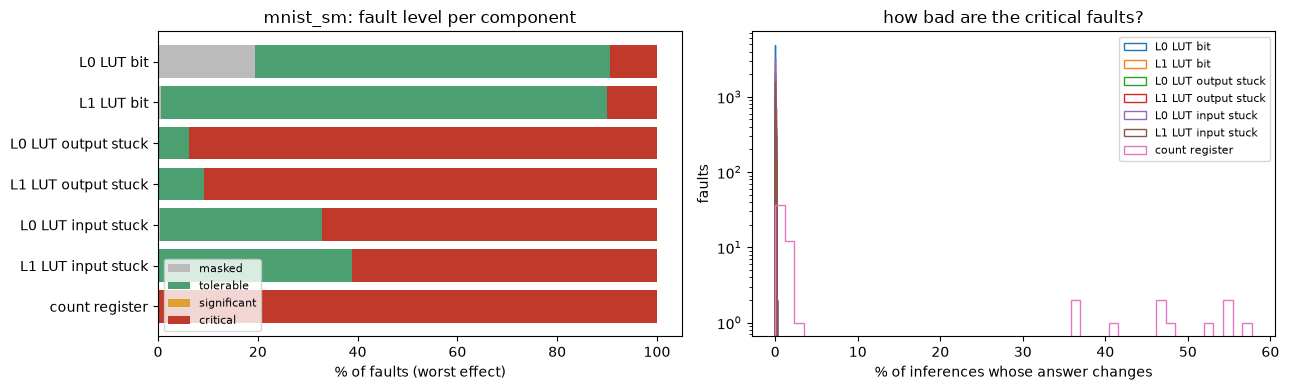

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
colors = {'masked': '#bbbbbb', 'tolerable': '#4c9f70', 'significant': '#e0a030', 'critical': '#c0392b'}
left = np.zeros(len(summary))
for lv in LEVELS:
    v = summary[f'faults: {lv} %'].values
    ax[0].barh(summary.component, v, left=left, color=colors[lv], label=lv); left += v
ax[0].invert_yaxis(); ax[0].set_xlabel('% of faults (worst effect)'); ax[0].legend(fontsize=8)
ax[0].set_title(f'{MODEL}: fault level per component')
for comp, g in allf.groupby('component', sort=False):
    d = g['critical % of inferences'][g.critical > 0]
    if len(d):
        ax[1].hist(d, bins=50, histtype='step', label=comp, log=True)
ax[1].set_xlabel('% of inferences whose answer changes'); ax[1].set_ylabel('faults'); ax[1].legend(fontsize=8)
ax[1].set_title('how bad are the critical faults?')
plt.tight_layout(); plt.savefig(f'{OUT}/single_faults.png', dpi=150); plt.show()

## Campaign 5: random bit flips at bit error rate *p* (reproduces arXiv 2603.22770's setup)

Every truth-table bit flips independently with probability *p*. We report accuracy (mean and worst 5% of trials), the share of inferences at each level, and the **tolerable BER**: the largest *p* whose mean accuracy drop is at most `ACC_THRESHOLD`.

In [ ]:
if BER_SAMPLES is not None and BER_SAMPLES < len(y):
    sub = np.sort(rng.choice(len(y), BER_SAMPLES, replace=False))
    bsim = DWNSim(spec, x_bits[sub], y[sub])
else:
    bsim = sim
t0 = time.time()
rec = []
for p in BER_LIST:
    for trial in range(BER_TRIALS):
        s = bsim.random_lut_flips(p, rng)
        rec.append(dict(p=p, trial=trial, acc=bsim.acc * 100 - s['drop_pp'], **s))
c5 = pd.DataFrame(rec)
for lv in ['tolerable', 'significant', 'critical']:
    c5[f'{lv} %'] = c5[lv] / bsim.N * 100
ber = c5.groupby('p').agg(bits_flipped=('bits_flipped', 'mean'), acc_mean=('acc', 'mean'),
                          acc_p5=('acc', lambda a: np.percentile(a, 5)), drop_mean=('drop_pp', 'mean'),
                          **{f'{lv} %': (f'{lv} %', 'mean') for lv in ['tolerable', 'significant', 'critical']}).reset_index()
ok = ber[ber.drop_mean <= ACC_THRESHOLD].p
print(f'{len(c5)} trials in {time.time()-t0:.1f}s on {bsim.N} samples | clean acc {bsim.acc*100:.2f}%')
print(f'tolerable BER (mean drop <= {ACC_THRESHOLD}pp):', ok.max() if len(ok) else 'below the smallest p tested')
ber.round(4)

KeyboardInterrupt: 

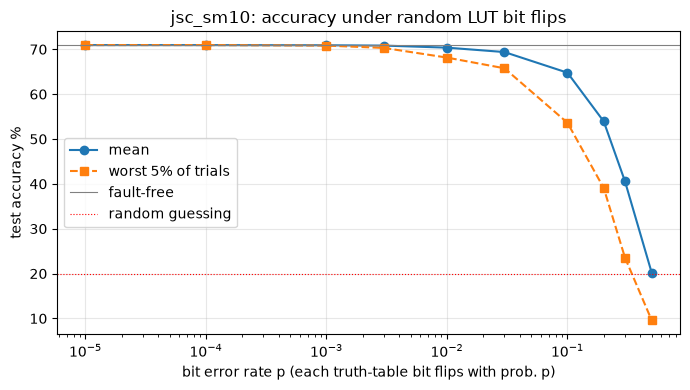

In [ ]:
plt.figure(figsize=(7, 4))
plt.semilogx(ber.p, ber.acc_mean, 'o-', label='mean')
plt.semilogx(ber.p, ber.acc_p5, 's--', label='worst 5% of trials')
plt.axhline(bsim.acc * 100, color='gray', lw=0.8, label='fault-free')
plt.axhline(100 / sim.K, color='red', lw=0.8, ls=':', label='random guessing')
plt.xlabel('bit error rate p (each truth-table bit flips with prob. p)'); plt.ylabel('test accuracy %')
plt.title(f'{MODEL}: accuracy under random LUT bit flips'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{OUT}/ber_curve.png', dpi=150); plt.show()

## Save everything

In [ ]:
for name, df in [('c1_lut_bit_flips', c1), ('c2_output_stuck', c2), ('c3_input_stuck', c3),
                 ('c4_count_register', c4), ('c5_ber_trials', c5), ('c5_ber_summary', ber)]:
    df.to_csv(f'{OUT}/{name}.csv', index=False)
print('saved to', os.path.abspath(OUT), ':', sorted(os.listdir(OUT)))

saved to c:\Users\youse\Downloads\DWN\faults\mnist_sm : ['c1_lut_bit_flips.csv', 'c2_output_stuck.csv', 'c3_input_stuck.csv', 'c4_count_register.csv', 'c5_ber_summary.csv', 'c5_ber_trials.csv', 'single_faults.png', 'summary.csv']


## Reading the results

* **Campaigns 1-3 vs 5.** Campaign 5 asks "how does the model degrade under many random upsets?" (the question prior work answered).
  Campaigns 1-3 ask "which single upset hurts, and where is it?", which is what you need to decide what to protect.
* **Campaign 4 is the popcount/argmax weak spot.** One upset in the top bit of a count register changes the answer for a large share
  of inferences, while a single LUT bit almost never does. That contrast is the motivation for selective hardening.
* **Not modelled yet** (needs the RTL or the FPGA): faults in the partial-sum and argmax pipeline registers, LUTs used by the popcount
  adders, clock/control logic, and multi-bit upsets. These are the next step, with Verilog simulation or Vivado essential bits.